In [1]:
# pip install tensorflow pandas numpy tldextract scikit-learn matplotlib seaborn keras
import tensorflow as tf
import pandas as pd
import numpy as np
import pickle
import re
import tldextract
from difflib import SequenceMatcher
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.layers import Input,Embedding, Conv1D, MaxPooling1D, GlobalMaxPooling1D, Dense, Dropout, LSTM, Concatenate, Masking
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import Precision, Recall
from tensorflow.keras.layers import Multiply
from keras import ops
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns
import json

In [2]:
# config.py
# Global configuration for CNN Phishing URL Detection project

# Character vocabulary allowed in URLs
VOCAB = "abcdefghijklmnopqrstuvwxyz0123456789/:.?&=%-_"

# Mapping each character to a unique integer
CHAR_TO_INT = {ch: idx + 1 for idx, ch in enumerate(VOCAB)}

# Reverse mapping for debugging
INT_TO_CHAR = {idx + 1: ch for idx, ch in enumerate(VOCAB)}

# Vocabulary size for Embedding layer
VOCAB_SIZE = len(VOCAB) + 1  # +1 for unknown/padding token

# Maximum allowed URL length for padding
URL_MAX_LEN = 200

# Size of embedding vectors learned by the model
EMBEDDING_DIM = 128

#CNN:
# INPUT
max_words = 1000
TEXT_MAX_LEN = 150

In [3]:
# clean_url.py
# Cleans and normalizes URLs + adds domain validation & typo detection.

# Trusted brand domains (add more if needed)
TRUSTED_DOMAINS = [
    "google.com", "youtube.com", "facebook.com", "instagram.com", "twitter.com",
    "amazon.com", "paypal.com", "netflix.com", "microsoft.com", "apple.com",
    "linkedin.com", "wikipedia.org", "github.com", "stackoverflow.com"
]

# Similarity threshold for typosquatting detection
SIMILARITY_THRESHOLD = 0.75


def is_similar(a, b):
    """Return similarity ratio between two strings."""
    return SequenceMatcher(None, a, b).ratio()


def is_typosquatted(domain):
    """Detect if domain is a fake version of a trusted brand."""
    for real_domain in TRUSTED_DOMAINS:
        similarity = is_similar(domain, real_domain)
        if similarity >= SIMILARITY_THRESHOLD and domain != real_domain:
            return True
    return False


def clean_url(url: str) -> str:
    """
    Cleans a URL AND applies security checks:
    - Detects invalid domains
    - Detects typosquatting (fake lookalike domains)
    - Removes protocol (http/https)
    - Removes 'www.'
    - Removes trailing slash
    - Converts to lowercase
    """
    #url = str(url)  Ensure input is a string

    if not isinstance(url, str):
        return "INVALID_DOMAIN"

    url = url.lower().strip()

    # Extract domain using tldextract
    extracted = tldextract.extract(url)
    domain = f"{extracted.domain}.{extracted.suffix}"

    # INVALID DOMAIN CHECK
    if extracted.suffix == "":
        return "INVALID_DOMAIN"

    # TYPOSQUATTING CHECK
    if is_typosquatted(domain):
        return "TYPOSQUAT"


    url = re.sub(r'^https?:\/\/', '', url)   # Remove http/https
    url = re.sub(r'^www\.', '', url)         # Remove www.

    if url.endswith("/"):
        url = url[:-1]                       # Remove trailing slash


    return url


In [4]:
# encode.py
# Converts URL string into numerical sequence for CNN input.

def encode_url(url: str):
    """
    Converts a URL into a list of integer-encoded characters.
    Unknown characters become 0.
    """
    url = url.lower().strip()  # normalize URL

    encoded = [CHAR_TO_INT.get(ch, 0) for ch in url]
    return encoded


def encode_and_pad(url: str):
    """
    Encodes URL and pads it to MAX_LEN for model input.
    """
    seq = encode_url(url)
    padded = pad_sequences([seq], maxlen=URL_MAX_LEN)
    return padded


In [5]:
#preprocessing for URL
dataset_path = "../data/CNN_data/train.csv"
df1 = pd.read_csv(dataset_path)
dataset_path2 = "../data/CNN_data/val.csv"
df2 = pd.read_csv(dataset_path2)
dataset_path3 = "../data/CNN_data/test.csv"
df3 = pd.read_csv(dataset_path3)

# df = df2
df = [df1, df2, df3]
df = pd.concat(df, ignore_index=True)

df.columns = ['url', 'label']
df['label'] = df['label'].apply(lambda x: 0 if x == 0 else 1)

print("[INFO] Cleaning URLs...")
df['cleaned_url'] = df['url'].apply(clean_url)

print("[INFO] Encoding URLs...")
df['encoded'] = df['cleaned_url'].apply(encode_url)


print("[INFO] Padding sequences...")
X_cnn = pad_sequences(df['encoded'].tolist(), maxlen=URL_MAX_LEN)
y_cnn = df['label'].values
df.shape, X_cnn.shape, y_cnn.shape
df.head()
df.label.value_counts()



[INFO] Cleaning URLs...
[INFO] Encoding URLs...
[INFO] Padding sequences...


label
0    427982
1    213011
Name: count, dtype: int64

Preprocessing, cleaning and encoding URLs is done above

Preprocessing, and tokenisation of Text below

In [6]:
lstm_dataset_path = "../data/combined_data.csv"
df_lstm = pd.read_csv(lstm_dataset_path, keep_default_na=False)

# remove URL filler
df_lstm["text"] = df_lstm["text"].str.replace("<URL>", " ", regex=False)
#remove email filler
df_lstm["text"] = df_lstm["text"].str.replace("<EMAIL>", " ", regex=False)
#remove phone filler
df_lstm["text"] = df_lstm["text"].str.replace("<PHONE>", " ", regex=False)
#lowercase all text
df_lstm["text"] = df_lstm["text"].str.lower()



X_lstm = df_lstm.text  #X contains the text messages (input)
Y_lstm = df_lstm.label  #Y contains the label corresponding to the text messages (target values)
le = LabelEncoder()
Y_lstm = le.fit_transform(Y_lstm)

# prints the two classes present, 'ham' and 'spam'
print(le.classes_) 

# prints a list of the label corresponding to each of the input input instances (or input text messages)
print(Y_lstm)
print(Y_lstm.shape)




[0 1]
[1 1 0 ... 1 1 1]
(114611,)


In [7]:
# Train / validation / test split
# 80% train, 10% validation, 10% test

sms_train, sms_temp, y_sms_train, y_sms_temp = train_test_split(
    X_lstm,
    Y_lstm,
    test_size=0.2,
    random_state=42,
    stratify=Y_lstm
)

sms_val, sms_test, y_sms_val, y_sms_test = train_test_split(
    sms_temp,
    y_sms_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_sms_temp
)

url_train, url_temp, y_url_train, y_url_temp = train_test_split(
    X_cnn,
    y_cnn,
    test_size=0.2,
    random_state=42,
    stratify=y_cnn
)

url_val, url_test, y_url_val, y_url_test = train_test_split(
    url_temp,
    y_url_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_url_temp
)

In [8]:
#tokenise for text data
tok = Tokenizer(num_words=max_words)

# only fit tokenizer on training data
tok.fit_on_texts(sms_train)

with open("lstm_tokenizer.pkl", "wb") as f:
    pickle.dump(tok, f)

# Train
sequences = tok.texts_to_sequences(sms_train)
sms_train_pad = tf.keras.preprocessing.sequence.pad_sequences(
    sequences,
    maxlen=TEXT_MAX_LEN
)

# Validation
val_sequences = tok.texts_to_sequences(sms_val)
sms_val_pad = tf.keras.preprocessing.sequence.pad_sequences(
    val_sequences,
    maxlen=TEXT_MAX_LEN
)

# Test
test_sequences = tok.texts_to_sequences(sms_test)
sms_test_pad = tf.keras.preprocessing.sequence.pad_sequences(
    test_sequences,
    maxlen=TEXT_MAX_LEN
)

In [9]:
#concatonate the two datasets 
n_url_train = len(url_train)
n_sms_train = len(sms_train_pad)

cnn_train = np.vstack([
    url_train,
    np.zeros((n_sms_train, URL_MAX_LEN), dtype=np.int32)
])

lstm_train = np.vstack([
    np.zeros((n_url_train, TEXT_MAX_LEN), dtype=np.int32),
    sms_train_pad
])

y_train = np.concatenate([
    y_url_train,
    y_sms_train
])

n_url_val = len(url_val)
n_sms_val = len(sms_val_pad)

cnn_val = np.vstack([
    url_val,
    np.zeros((n_sms_val, URL_MAX_LEN), dtype=np.int32)
])

lstm_val = np.vstack([
    np.zeros((n_url_val, TEXT_MAX_LEN), dtype=np.int32),
    sms_val_pad
])

y_val = np.concatenate([
    y_url_val,
    y_sms_val
])

n_url_test = len(url_test)
n_sms_test = len(sms_test_pad)

cnn_test = np.vstack([
    url_test,
    np.zeros((n_sms_test, URL_MAX_LEN), dtype=np.int32)
])

lstm_test = np.vstack([
    np.zeros((n_url_test, TEXT_MAX_LEN), dtype=np.int32),
    sms_test_pad
])

y_test = np.concatenate([
    y_url_test,
    y_sms_test
])

# Shuffle training
idx = np.random.permutation(len(y_train))

cnn_train = cnn_train[idx]
lstm_train = lstm_train[idx]
y_train = y_train[idx]


# Shuffle validation
idx = np.random.permutation(len(y_val))

cnn_val = cnn_val[idx]
lstm_val = lstm_val[idx]
y_val = y_val[idx]


# Shuffle test
idx = np.random.permutation(len(y_test))

cnn_test = cnn_test[idx]
lstm_test = lstm_test[idx]
y_test = y_test[idx]

print(f"cnn_train:  {cnn_train.shape}")
print(f"lstm_train: {lstm_train.shape}")
print(f"y_train:    {y_train.shape}")

print(f"cnn_test:   {cnn_test.shape}")
print(f"lstm_test:  {lstm_test.shape}")
print(f"y_test:     {y_test.shape}")

cnn_train:  (604482, 200)
lstm_train: (604482, 150)
y_train:    (604482,)
cnn_test:   (75562, 200)
lstm_test:  (75562, 150)
y_test:     (75562,)


In [10]:
# input
max_words = 1000
TEXT_MAX_LEN = 150

cnn_input  = Input(shape=(URL_MAX_LEN,),  name="cnn_input",  dtype=tf.int32)
lstm_input = Input(shape=(TEXT_MAX_LEN,), name="lstm_input", dtype=tf.int32)


# emedding
x = Embedding(
    input_dim=VOCAB_SIZE,
    output_dim=EMBEDDING_DIM,
    input_length=URL_MAX_LEN,
    dtype="float32"
)(cnn_input)

# CNN layers
x = Conv1D(
    filters=256,
    kernel_size=5,
    activation='relu'
)(x)
x = MaxPooling1D(pool_size=2)(x)
x = Conv1D(
    filters=128,
    kernel_size=3,
    activation='relu'
)(x)
x = GlobalMaxPooling1D()(x)

# feature extraction
x = Dense(64, activation='relu')(x)
x = Dropout(0.3)(x) 

# feature vector
cnn_features = x

# CNN-only output
cnn_output = Dense(
    1,
    activation='sigmoid',
    name='cnn_output'
)(cnn_features)

# if output is 0, then multiply the cnn_features by 0 to ensure that the features are not used in the final output
url_present = ops.cast(
    ops.sum(cnn_input, axis=1, keepdims=True) > 0,
    "float32"
)
# multiply the cnn_features by url_present to ensure that the features are not used in the final output if the output is 0
cnn_features = Multiply()([
    cnn_features,
    url_present
])



# LSTM layers
y = Embedding(
    input_dim=max_words,
    output_dim=50,
    mask_zero=True
)(lstm_input)
y = LSTM(64, unroll=True)(y)

y = Dense(256, activation='relu')(y)
y = Dropout(0.5)(y) 
lstm_features = y

# LSTM-only output
lstm_output = Dense(
    1,
    activation='sigmoid',
    name='lstm_output'
)(lstm_features)

# detect whether SMS text is present
sms_present = ops.cast(
    ops.sum(lstm_input, axis=1, keepdims=True) > 0,
    "float32"
)

# zero out LSTM features for URL-only samples
lstm_features = Multiply()([
    lstm_features,
    sms_present
])


# merge features
combined = Concatenate()([
    cnn_features,
    lstm_features
])

z = Dense(128, activation='relu')(combined)
z = Dropout(0.5)(z) 

hybrid_output = Dense(
    1,
    activation='sigmoid',
    name='hybrid_output'
)(z)



#final model
model = Model(
    inputs=[cnn_input, lstm_input],
    outputs=[
        hybrid_output,
        cnn_output,
        lstm_output
    ]
)

model.compile(
    optimizer='adam',

    loss={
        'hybrid_output': 'binary_crossentropy',
        'cnn_output': 'binary_crossentropy',
        'lstm_output': 'binary_crossentropy'
    },

    loss_weights={
        'hybrid_output': 0.5,
        'cnn_output': 0.2,
        'lstm_output': 0.3
    },

    weighted_metrics={
        'hybrid_output': [
            'accuracy',
            Precision(name='precision'),
            Recall(name='recall')
        ],
        'cnn_output': [
            'accuracy',
            Precision(name='precision'),
            Recall(name='recall')
        ],
        'lstm_output': [
            'accuracy',
            Precision(name='precision'),
            Recall(name='recall')
        ]
    }
)


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:103: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [11]:
# create sample weights and train model

lstm_weights_train = np.array([
    1 if lstm_train[i].sum() != 0 else 0
    for i in range(len(lstm_train))
], dtype=np.float32)

lstm_weights_val = np.array([
    1 if lstm_val[i].sum() != 0 else 0
    for i in range(len(lstm_val))
], dtype=np.float32)

lstm_weights_test = np.array([
    1 if lstm_test[i].sum() != 0 else 0
    for i in range(len(lstm_test))
], dtype=np.float32)


cnn_weights_train = np.array([
    1 if cnn_train[i].sum() != 0 else 0
    for i in range(len(cnn_train))
], dtype=np.float32)

cnn_weights_val = np.array([
    1 if cnn_val[i].sum() != 0 else 0
    for i in range(len(cnn_val))
], dtype=np.float32)

cnn_weights_test = np.array([
    1 if cnn_test[i].sum() != 0 else 0
    for i in range(len(cnn_test))
], dtype=np.float32)


hybrid_weights_train = np.ones(len(y_train), dtype=np.float32)
hybrid_weights_val = np.ones(len(y_val), dtype=np.float32)
hybrid_weights_test = np.ones(len(y_test), dtype=np.float32)


history = model.fit(
    [cnn_train, lstm_train],
    [y_train, y_train, y_train],
    sample_weight=[
        hybrid_weights_train,
        cnn_weights_train,
        lstm_weights_train,
    ],
    epochs=20, 
    batch_size=64, 
    validation_data=(
        [cnn_val, lstm_val],
        [y_val, y_val, y_val],
        [
            hybrid_weights_val,
            cnn_weights_val,
            lstm_weights_val
        ]
    )
)


Epoch 1/20
9446/9446 ━━━━━━━━━━━━━━━━━━━━ 1096s 114ms/step - cnn_output_accuracy: 0.8796 - cnn_output_loss: 0.2319 - cnn_output_precision: 0.8626 - cnn_output_recall: 0.7584 - hybrid_output_accuracy: 0.8927 - hybrid_output_loss: 0.2502 - hybrid_output_precision: 0.8878 - hybrid_output_recall: 0.8049 - loss: 0.1761 - lstm_output_accuracy: 0.9677 - lstm_output_loss: 0.0154 - lstm_output_precision: 0.9667 - lstm_output_recall: 0.9720 - val_cnn_output_accuracy: 0.9049 - val_cnn_output_loss: 0.1890 - val_cnn_output_precision: 0.8690 - val_cnn_output_recall: 0.8406 - val_hybrid_output_accuracy: 0.9137 - val_hybrid_output_loss: 0.2034 - val_hybrid_output_precision: 0.8859 - val_hybrid_output_recall: 0.8739 - val_loss: 0.1439 - val_lstm_output_accuracy: 0.9703 - val_lstm_output_loss: 0.0146 - val_lstm_output_precision: 0.9810 - val_lstm_output_recall: 0.9622
Epoch 2/20
9446/9446 ━━━━━━━━━━━━━━━━━━━━ 1162s 123ms/step - cnn_output_accuracy: 0.9106 - cnn_output_loss: 0.1767 - cnn_output_precision

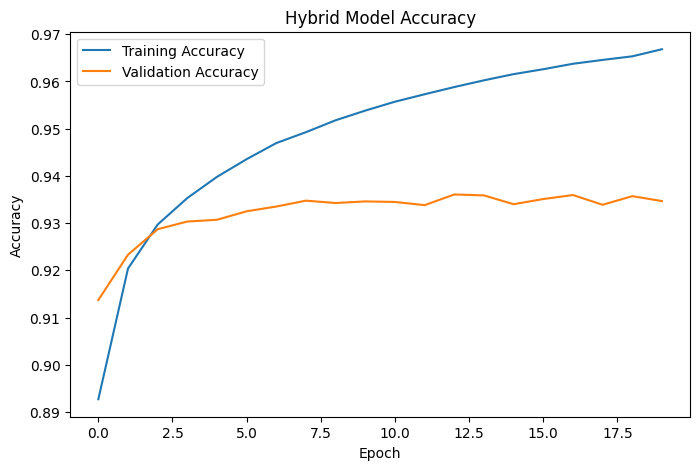

In [12]:
# Plot hybrid model training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['hybrid_output_accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_hybrid_output_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Hybrid Model Accuracy')
plt.legend()
plt.show()

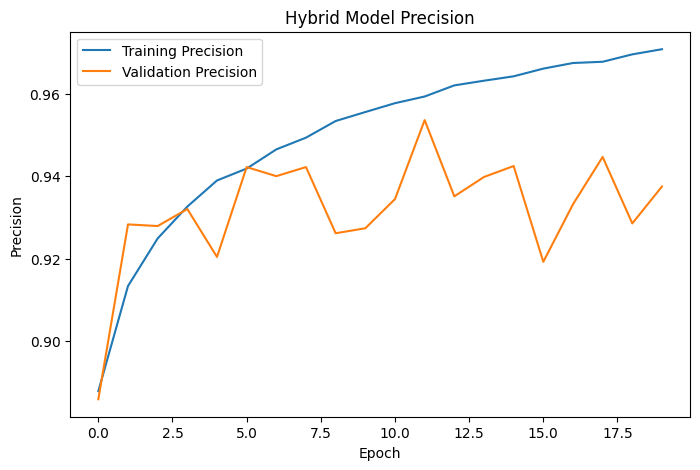

In [13]:
# Plot hybrid model training and validation precision
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['hybrid_output_precision'],
    label='Training Precision'
)

plt.plot(
    history.history['val_hybrid_output_precision'],
    label='Validation Precision'
)

plt.xlabel('Epoch')
plt.ylabel('Precision')
plt.title('Hybrid Model Precision')
plt.legend()
plt.show()

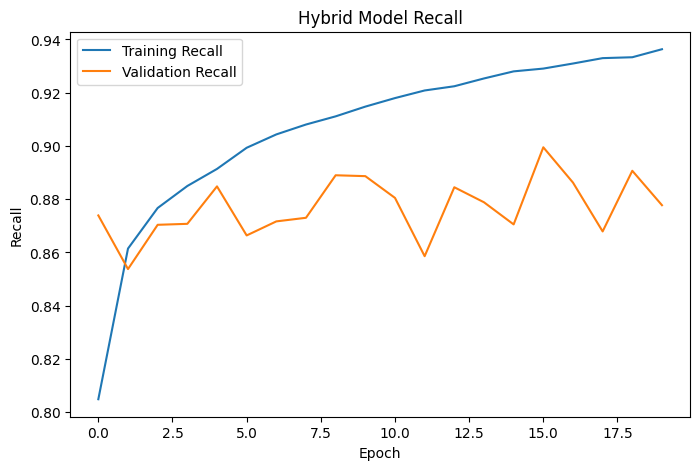

In [14]:
# Plot hybrid model training and validation recall
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['hybrid_output_recall'],
    label='Training Recall'
)

plt.plot(
    history.history['val_hybrid_output_recall'],
    label='Validation Recall'
)

plt.xlabel('Epoch')
plt.ylabel('Recall')
plt.title('Hybrid Model Recall')
plt.legend()
plt.show()

In [15]:
# evaluate with test set with sample weights
test_results = model.evaluate(
    [cnn_test, lstm_test],
    [y_test, y_test, y_test],
    sample_weight=[
        hybrid_weights_test,
        cnn_weights_test,
        lstm_weights_test
    ]
)

2362/2362 ━━━━━━━━━━━━━━━━━━━━ 41s 18ms/step - cnn_output_accuracy: 0.9268 - cnn_output_loss: 0.1957 - cnn_output_precision: 0.9206 - cnn_output_recall: 0.8532 - hybrid_output_accuracy: 0.9348 - hybrid_output_loss: 0.2090 - hybrid_output_precision: 0.9373 - hybrid_output_recall: 0.8782 - loss: 0.1506 - lstm_output_accuracy: 0.9800 - lstm_output_loss: 0.0232 - lstm_output_precision: 0.9796 - lstm_output_recall: 0.9825



===== Without weights =====

Hybrid (n=75562, threshold=0.5)
Accuracy:  93.48%
Precision: 93.73%
Recall:    87.82%
F1-score:  90.68%
[[46647  1604]
 [ 3326 23985]]

CNN (n=75562, threshold=0.5)
Accuracy:  85.83%
Precision: 92.06%
Recall:    66.54%
F1-score:  77.25%
[[46683  1568]
 [ 9137 18174]]

LSTM (n=75562, threshold=0.5)
Accuracy:  43.00%
Precision: 38.77%
Recall:    99.62%
F1-score:  55.82%
[[ 5287 42964]
 [  105 27206]]

===== With weights =====

Hybrid (n=75562, threshold=0.5)
Accuracy:  93.48%
Precision: 93.73%
Recall:    87.82%
F1-score:  90.68%
[[46647  1604]
 [ 3326 23985]]

CNN (n=64100, threshold=0.5)
Accuracy:  92.68%
Precision: 92.06%
Recall:    85.32%
F1-score:  88.56%
[[41231  1568]
 [ 3127 18174]]

LSTM (n=11411, threshold=0.5)
Accuracy:  98.00%
Precision: 97.96%
Recall:    98.25%
F1-score:  98.10%
[[5287  123]
 [ 105 5896]]


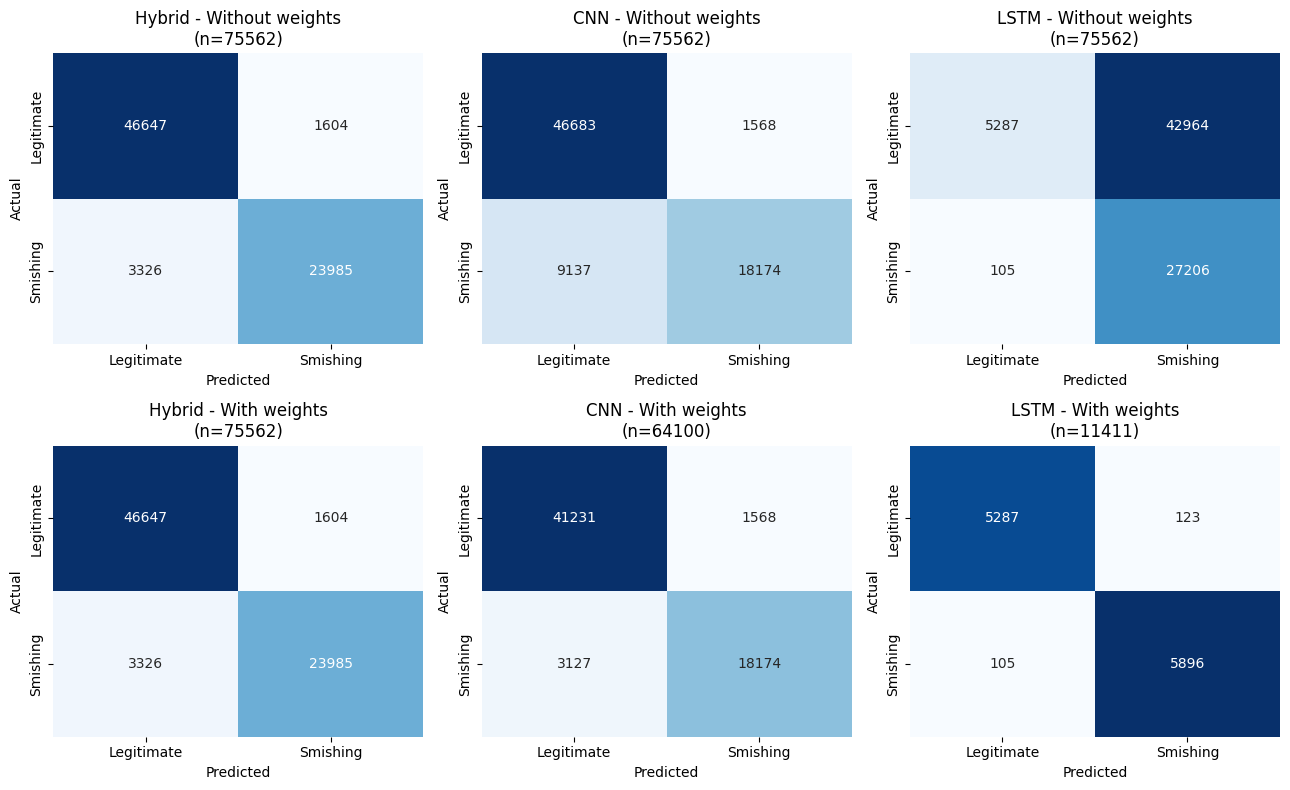

In [16]:
THRESH = {"Hybrid": 0.5, "CNN": 0.5, "LSTM": 0.5}

predictions = model.predict([cnn_test, lstm_test], verbose=0)
y_test = np.asarray(y_test).ravel()

# output order: hybrid, CNN, LSTM
outputs = {
    "Hybrid": (predictions[0] >= THRESH["Hybrid"]).astype(int).flatten(),
    "CNN":    (predictions[1] >= THRESH["CNN"]).astype(int).flatten(),
    "LSTM":   (predictions[2] >= THRESH["LSTM"]).astype(int).flatten(),
}

all_rows  = np.ones(len(y_test), dtype=bool)
text_rows = lstm_test.sum(axis=1) != 0
url_rows  = cnn_test.sum(axis=1) != 0

# Rows each output is scored on, for each setting
settings = {
    "Without weights": {"Hybrid": all_rows, "CNN": all_rows, "LSTM": all_rows},
    "With weights":    {"Hybrid": all_rows, "CNN": url_rows, "LSTM": text_rows},
}

labels = ["Legitimate", "Smishing"]
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for r, (setting, masks) in enumerate(settings.items()):
    print(f"\n===== {setting} =====")
    for c, (name, y_pred) in enumerate(outputs.items()):
        m = masks[name]
        print(f"\n{name} (n={m.sum()}, threshold={THRESH[name]})")
        print(f"Accuracy:  {accuracy_score(y_test[m], y_pred[m]) * 100:.2f}%")
        print(f"Precision: {precision_score(y_test[m], y_pred[m], zero_division=0) * 100:.2f}%")
        print(f"Recall:    {recall_score(y_test[m], y_pred[m], zero_division=0) * 100:.2f}%")
        print(f"F1-score:  {f1_score(y_test[m], y_pred[m], zero_division=0) * 100:.2f}%")

        cm = confusion_matrix(y_test[m], y_pred[m])
        print(cm)
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                    xticklabels=labels, yticklabels=labels, ax=axes[r, c])
        axes[r, c].set_title(f"{name} - {setting}\n(n={m.sum()})")
        axes[r, c].set_xlabel("Predicted")
        axes[r, c].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices_weighted_vs_unweighted.png", dpi=300)
plt.show()

In [17]:
# predict, then identify best threshold value for smishing messages
preds = model.predict([cnn_test, lstm_test], verbose=0)
hybrid_p = preds[0].flatten()

text_rows = lstm_test.sum(axis=1) != 0
url_rows  = cnn_test.sum(axis=1) != 0

def threshold_table(name, y, p, mask, thresholds=(0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7)):
    print(f"\n{name} (n={mask.sum()})")
    print("thr    acc    prec   rec    f1")
    for t in thresholds:
        pred = (p[mask] > t).astype(int)
        y_m = y[mask]
        print(f"{t:.2f}  {accuracy_score(y_m, pred):.4f} "
              f"{precision_score(y_m, pred, zero_division=0):.4f} "
              f"{recall_score(y_m, pred):.4f} "
              f"{f1_score(y_m, pred):.4f}")

threshold_table("Hybrid on text rows", y_test, hybrid_p, text_rows)
threshold_table("Hybrid on URL rows",  y_test, hybrid_p, url_rows)
threshold_table("Hybrid on all rows",  y_test, hybrid_p, np.ones(len(y_test), bool))


Hybrid on text rows (n=11411)
thr    acc    prec   rec    f1
0.30  0.9792 0.9768 0.9838 0.9803
0.35  0.9794 0.9772 0.9838 0.9805
0.40  0.9799 0.9784 0.9835 0.9810
0.45  0.9798 0.9788 0.9830 0.9809
0.50  0.9800 0.9792 0.9828 0.9810
0.55  0.9801 0.9794 0.9828 0.9811
0.60  0.9796 0.9800 0.9812 0.9806
0.65  0.9790 0.9805 0.9795 0.9800
0.70  0.9775 0.9809 0.9762 0.9785

Hybrid on URL rows (n=64100)
thr    acc    prec   rec    f1
0.30  0.9216 0.8635 0.9077 0.8850
0.35  0.9248 0.8811 0.8943 0.8877
0.40  0.9269 0.9001 0.8773 0.8886
0.45  0.9271 0.9166 0.8589 0.8868
0.50  0.9268 0.9244 0.8491 0.8852
0.55  0.9260 0.9301 0.8404 0.8830
0.60  0.9257 0.9362 0.8332 0.8817
0.65  0.9248 0.9413 0.8252 0.8794
0.70  0.9236 0.9467 0.8160 0.8765

Hybrid on all rows (n=75562)
thr    acc    prec   rec    f1
0.30  0.9298 0.8863 0.9245 0.9050
0.35  0.9325 0.9007 0.9140 0.9073
0.40  0.9344 0.9163 0.9007 0.9084
0.45  0.9350 0.9310 0.8859 0.9079
0.50  0.9348 0.9373 0.8782 0.9068
0.55  0.9341 0.9418 0.8714 0.9053


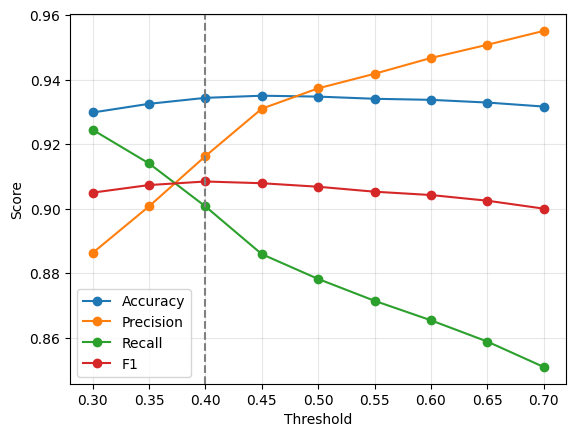

In [18]:
ts = np.arange(0.3, 0.71, 0.05)
p = hybrid_p.ravel()
for name, f in [("Accuracy", accuracy_score), ("Precision", precision_score),
                ("Recall", recall_score), ("F1", f1_score)]:
    plt.plot(ts, [f(y_test, p > t) for t in ts], marker="o", label=name)

plt.axvline(0.4, color="grey", linestyle="--")
plt.xlabel("Threshold"); plt.ylabel("Score"); plt.legend(); plt.grid(alpha=0.3)
plt.savefig("threshold.png", dpi=300)

In [19]:
# load tokenizer
with open("lstm_tokenizer.pkl", "rb") as f:
    tokenizer = pickle.load(f)

#save as json file - for android app
with open("word_index.json", "w") as f:
    json.dump(tokenizer.word_index, f)

# Save
model.save("smishing_model_keras.keras")

In [20]:
# load from saved file, not memory
model = tf.keras.models.load_model("smishing_model_keras.keras")

#convert to inference only TFLite model
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS,
    tf.lite.OpsSet.SELECT_TF_OPS
]

tflite_model = converter.convert()
with open("model.tflite", "wb") as f:
    f.write(tflite_model)

print(f"Model size: {len(tflite_model) / 1024:.1f} KB")

INFO:tensorflow:Assets written to: /var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7/assets


INFO:tensorflow:Assets written to: /var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7/assets


Saved artifact at '/var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 200), dtype=tf.int32, name='cnn_input'), TensorSpec(shape=(None, 150), dtype=tf.int32, name='lstm_input')]
Output Type:
  List[TensorSpec(shape=(None, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None), TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)]
Captures:
  4401325904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428823568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428828944: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428823760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428827600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428822992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428826064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  6428827216: TensorSpec(shape=(), d

W0000 00:00:1793206212.363840 5631736 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793206212.363966 5631736 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793206212.368586 5631736 reader.cc:83] Reading SavedModel from: /var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7
I0000 00:00:1793206212.372735 5631736 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793206212.372741 5631736 reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7
I0000 00:00:1793206212.426812 5631736 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793206212.431168 5631736 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793206212.584220 5631736 loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/s7/t36hzs8174q3dm1vzf9xzd3c0000gn/T/tmp5j4t8nk7
I0000 00:00:1793206212.682925 5631736 lo

Model size: 2138.8 KB
